# Visualisasi Eksperimen RankUp + Augmentasi

| § | Eksperimen | Seed | Optuna | Sumber |
|---|---|---|---|---|
| 1–3 | 6 augmentasi vs Tanpa RankUp, 3 dataset utama + 13 dataset + metode lain | 1 (42) | tidak (weak = 0, strong = 0.5) | `hasil/usulan-semua/results.jsonl` |
| 4 | 6 augmentasi, 3 dataset utama (run 5 Nov 2026) | 5 | ya, 40 trial | `hasil/ringkasan-5seed-40trial.csv`, `hasil/ta-5seed-40trial-20261105/` |

Semua run maks 120 epoch, split data sama. Semua angka adalah skor **test**.

| Tugas | Metrik | Arah |
|---|---|---|
| Ordinal | QWK (Quadratic Weighted Kappa) | ↑ lebih tinggi lebih baik |
| Klasifikasi | Macro F1-score | ↑ lebih tinggi lebih baik |
| Regresi | MSE (Mean Squared Error) | ↓ lebih rendah lebih baik |

- **Tanpa RankUp** = model TabM yang sama, hanya belajar dari data berlabel (bobot loss unlabeled = 0).
- **RankUp + augmentasi** = TabM + pseudo-label dari data unlabeled, dengan salah satu dari 6 augmentasi
  (TabCutMix, TabCutMix+, SCARF, Range-limited, Gaussian, Zero-out).

Di setiap tabel warna menunjukkan peringkat dalam satu kolom: **biru tua = terbaik**, terang = terburuk.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

HASIL = Path('hasil')
GAMBAR = HASIL / 'gambar'
GAMBAR.mkdir(exist_ok=True)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 9, 'axes.titlesize': 10, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'axes.axisbelow': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6, 'axes.edgecolor': '#8a8984',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e', 'legend.frameon': False,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
})

METODE = {'none': 'Tanpa RankUp', 'def_tabcutmix': 'RankUp + TabCutMix', 'def_tabcutmix_plus': 'RankUp + TabCutMix+',
          'def_scarf': 'RankUp + SCARF', 'def_range_limited': 'RankUp + Range-limited',
          'def_gaussian': 'RankUp + Gaussian', 'def_zero_out': 'RankUp + Zero-out'}
METRIK = {'ordinal_regression': ('qwk', 1, 'QWK ↑'), 'classification': ('macro_f1', 1, 'Macro F1 ↑'),
          'regression': ('mse', -1, 'MSE ↓')}
NAMA_DS = {'nhanes': 'NHANES', 'pendigits': 'Pen Digits', 'superconductivity': 'Superconductivity'}
SINGKAT = {'nhanes': 'NHANES', 'pendigits': 'Pen Digits', 'superconductivity': 'Supercond.', 'adult_income': 'Adult',
           'bank_marketing': 'Bank Mkt.', 'cmc': 'CMC', 'diabetes_pima': 'Diabetes', 'satimage': 'Satimage',
           'esl': 'ESL', 'lev': 'LEV', 'melbourne_airbnb': 'Melbourne', 'student_performance': 'Student',
           'grid_stability': 'Grid Stab.'}
# MSE Grid Stability sangat kecil; ditampilkan dalam satuan 10^-5 supaya terbaca.
SKALA = {'grid_stability': (1e5, ' (×10⁻⁵)')}

rows = []
for r in map(json.loads, open(HASIL / 'usulan-semua' / 'results.jsonl')):
    if r['seed'] == 42 and r['name'] in METODE:
        metric, sign, label = METRIK[r['task']]
        rows.append({'metode': METODE[r['name']], 'dataset': r['dataset'], 'pct': r['label_percent'], 'task': r['task'],
                     'metrik': label, 'sign': sign, 'test': r['test'][metric]})
data = pd.DataFrame(rows).drop_duplicates(['metode', 'dataset', 'pct'], keep='last')
data['rank'] = (data.test * data.sign).groupby([data.dataset, data.pct]).rank(ascending=False)


def angka(v):
    return f'{v:.1f}' if v >= 10 else f'{v:.2f}' if v >= 1 else f'{v:.3f}'


def urutan(d):
    # Urutan metode dari rata-rata peringkat terbaik ke terburuk.
    return d.groupby('metode')['rank'].mean().sort_values()


def tabel_warna(ax, d, urut=None, kanan=True):
    # Baris = metode (terbaik di atas), kolom = (dataset, % label).
    # Teks = nilai metrik + peringkat (#1 = terbaik di kolom itu); warna = peringkat.
    urut = urutan(d) if urut is None else urut
    nilai = d.pivot_table(index='metode', columns=['dataset', 'pct'], values='test').loc[urut.index]
    skala = [SKALA.get(ds, (1, ''))[0] for ds, _ in nilai.columns]
    std = (d.pivot_table(index='metode', columns=['dataset', 'pct'], values='std').loc[nilai.index, nilai.columns]
           * skala if 'std' in d else None)
    rank = d.pivot_table(index='metode', columns=['dataset', 'pct'], values='rank').loc[nilai.index, nilai.columns]
    ax.imshow(rank.values, cmap='Blues_r', vmin=1, vmax=len(nilai) + 2, aspect='auto')
    ax.grid(False)
    ax.set_yticks(range(len(nilai)), [f'{i}. {m}' for i, m in enumerate(nilai.index, start=1)])
    for label in ax.get_yticklabels():
        if 'Tanpa RankUp' in label.get_text():
            label.set_fontweight('bold')
    if kanan:
        ax.text(nilai.shape[1] - 0.4, -0.75, 'rata-rata\nperingkat', fontsize=7.5, color='#52514e', va='bottom')
        for i, v in enumerate(urut.values):
            ax.text(nilai.shape[1] - 0.4, i, f'{v:.2f}', va='center', fontsize=8.5, fontweight='bold')
    nilai = nilai * skala
    ax.set_xticks(range(nilai.shape[1]), [f'{SINGKAT[ds]}{SKALA.get(ds, (1, ""))[1]}\n{p}%' for ds, p in nilai.columns],
                  fontsize=7.5)
    for i in range(nilai.shape[0]):
        for j in range(nilai.shape[1]):
            if pd.notna(nilai.iat[i, j]):
                sd = '' if std is None else f' ± {angka(std.iat[i, j])}'
                ax.text(j, i, f'{angka(nilai.iat[i, j])}{sd}\n#{rank.iat[i, j]:g}', ha='center', va='center', fontsize=7,
                        color='white' if rank.iat[i, j] <= 2 else '#0b0b0b',
                        fontweight='bold' if rank.iat[i, j] == 1 else 'normal')
    return nilai


def simpan(fig, nama):
    fig.savefig(GAMBAR / f'{nama}.png', bbox_inches='tight')

## 1. TANPA Optuna, 1 seed (42): tiga dataset utama

> Bagian 1–3 memakai run **tanpa Optuna, hanya seed 42**. Hasil **Optuna 40 trial + 5 seed** ada di **§4**.

**Cara membaca tabel:**

- Satu **kolom** = satu dataset + satu % label. Di setiap kolom, ketujuh metode diberi peringkat.
- **#** = peringkat metode di kolom itu: **#1 = terbaik**, #7 = terburuk. Untuk QWK dan Macro F1 nilai tertinggi
  yang #1; untuk MSE nilai **terendah** yang #1. Warna mengikuti peringkat (biru tua = baik).
- **Peringkat desimal (#1.5, #5.5)** = beberapa metode punya nilai **sama persis**, jadi berbagi peringkat.
  Contoh NHANES 30%: Gaussian dan Zero-out sama-sama 0.334 → berbagi peringkat 1 dan 2 → masing-masing **#1.5**;
  empat metode bernilai 0.324 → berbagi peringkat 4–7 → masing-masing **#5.5**.
- **Angka tebal di kanan** = rata-rata dari semua # di baris itu. Contoh Range-limited:
  (6 + 2 + 5.5 + 1 + 1 + 1 + 2 + 3 + 3) / 9 = **2.72**.
- **Baris diurutkan** dari rata-rata peringkat terkecil (atas = terbaik) ke terbesar (bawah = terburuk).

Cara membaca yang sama berlaku untuk semua tabel warna di notebook ini.

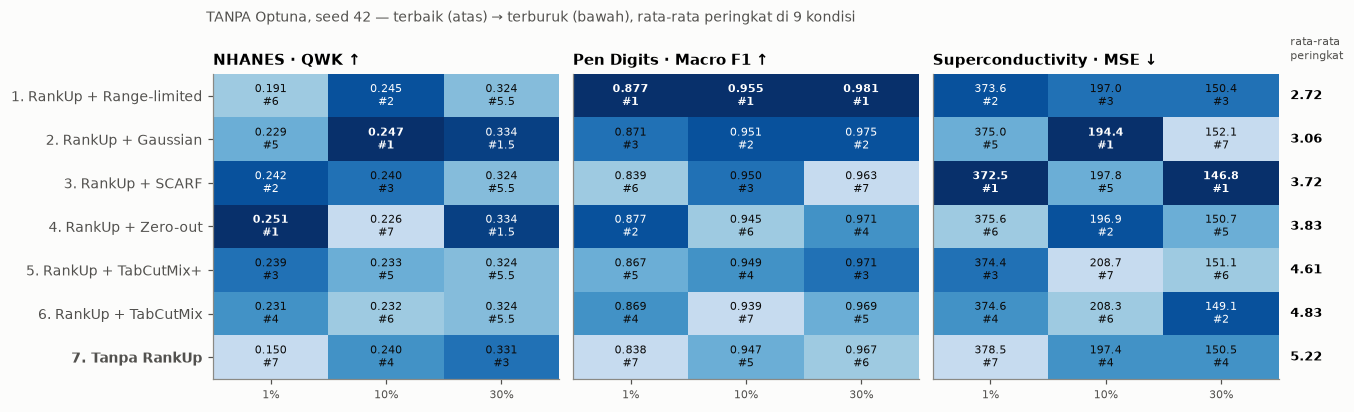

In [2]:
utama = data[data.dataset.isin(list(NAMA_DS))]
urut3 = urutan(utama)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), sharey=True, gridspec_kw={'wspace': 0.04})
for ax, ds in zip(axes, NAMA_DS):
    d = data[data.dataset == ds]
    tabel_warna(ax, d, urut3, kanan=ds == 'superconductivity')
    ax.set_xticks(range(3), ['1%', '10%', '30%'])
    ax.set_title(f'{NAMA_DS[ds]} · {d.metrik.iat[0]}')
    if ds != 'nhanes':
        ax.tick_params(left=False)
fig.suptitle('TANPA Optuna, seed 42 — terbaik (atas) → terburuk (bawah), rata-rata peringkat di 9 kondisi',
             x=0.12, ha='left', y=1.04, fontsize=9, color='#52514e')
simpan(fig, '1_tiga_dataset')

- **Label 1%**: semua RankUp lebih baik dari Tanpa RankUp di ketiga dataset
  (NHANES QWK 0.150 → 0.191–0.251; Pen Digits F1 0.838 → 0.839–0.877; Superconductivity MSE 378.5 → 372.5–375.6).
- **Label 30%**: selisihnya kecil. Di NHANES Tanpa RankUp (QWK 0.331) mengalahkan sebagian besar RankUp.
- NHANES 10% dan Superconductivity 10%: beberapa augmentasi lebih buruk dari Tanpa RankUp
  (TabCutMix/TabCutMix+ MSE 208 vs 197).
- Pemenang tiap kolom berganti-ganti: tidak ada augmentasi yang selalu terbaik.

## 2. TANPA Optuna, 1 seed (42): semua 13 dataset, dipisah per tugas

LEV, ESL dan Student Performance tidak punya split 1% (label terlalu sedikit), jadi hanya 10% dan 30%.

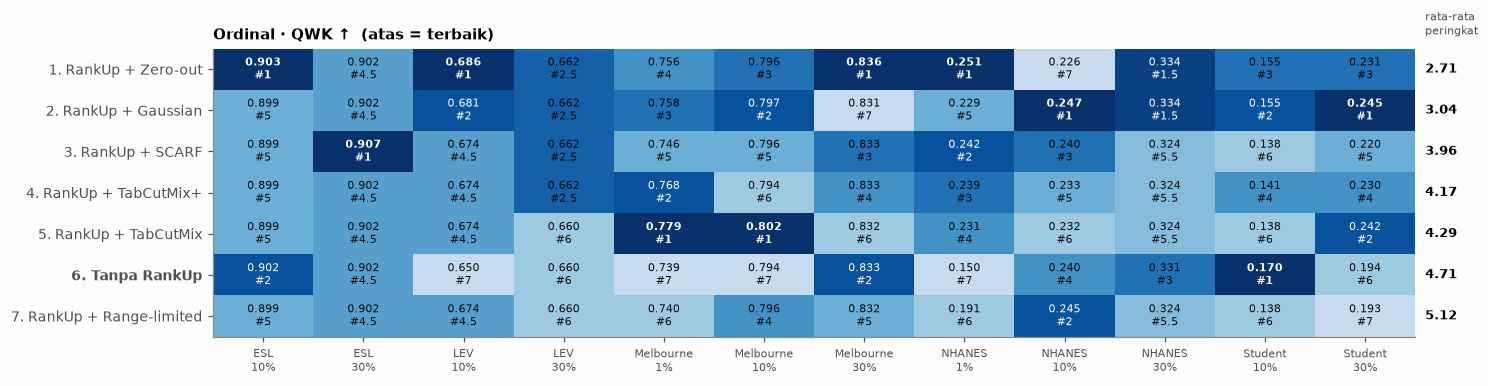

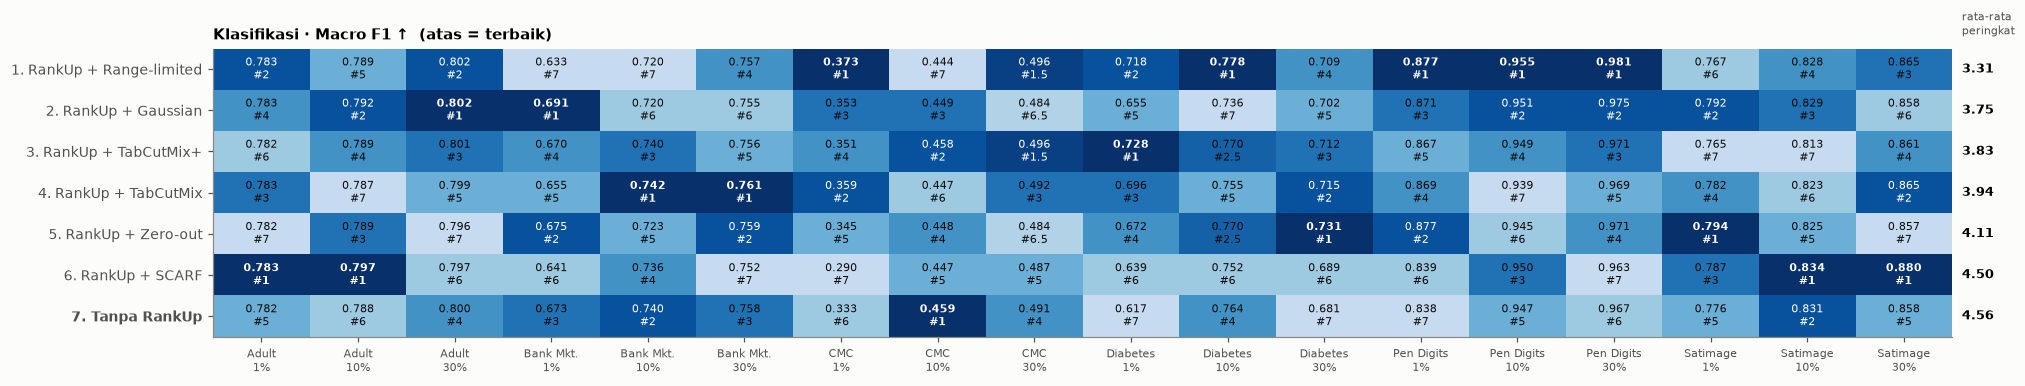

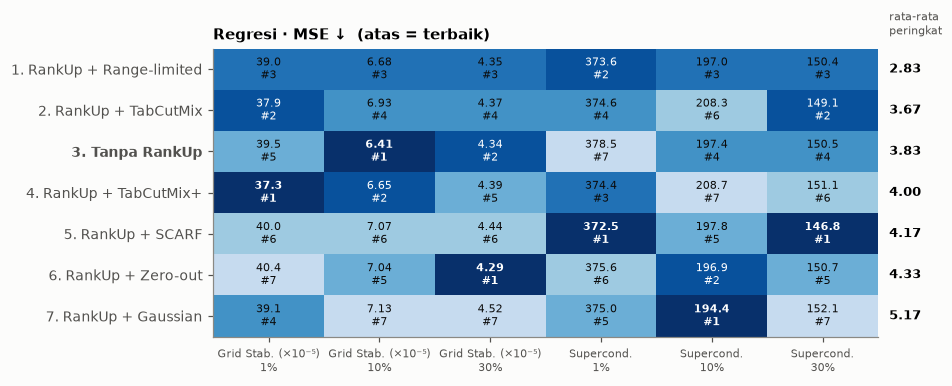

In [3]:
for task, nama_file in (('ordinal_regression', '2a_ordinal_qwk'), ('classification', '2b_klasifikasi_f1'),
                        ('regression', '2c_regresi_mse')):
    d = data[data.task == task]
    n_kolom = d[['dataset', 'pct']].drop_duplicates().shape[0]
    fig, ax = plt.subplots(figsize=(1.05 * n_kolom + 1.5, 3.4))
    tabel_warna(ax, d)
    judul = {'ordinal_regression': 'Ordinal · QWK ↑', 'classification': 'Klasifikasi · Macro F1 ↑',
             'regression': 'Regresi · MSE ↓'}[task]
    ax.set_title(judul + '  (atas = terbaik)')
    simpan(fig, nama_file)
    plt.show()

,rata-rata peringkat,lebih baik dari Tanpa RankUp,kondisi,jumlah #1
metode,,,,
RankUp + Zero-out,3.68,22,36,7
RankUp + Gaussian,3.75,22,36,5
RankUp + Range-limited,3.83,21,36,5
RankUp + TabCutMix+,3.97,19,36,2
RankUp + TabCutMix,4.01,19,36,4
RankUp + SCARF,4.26,19,36,7
Tanpa RankUp,4.49,0,36,3


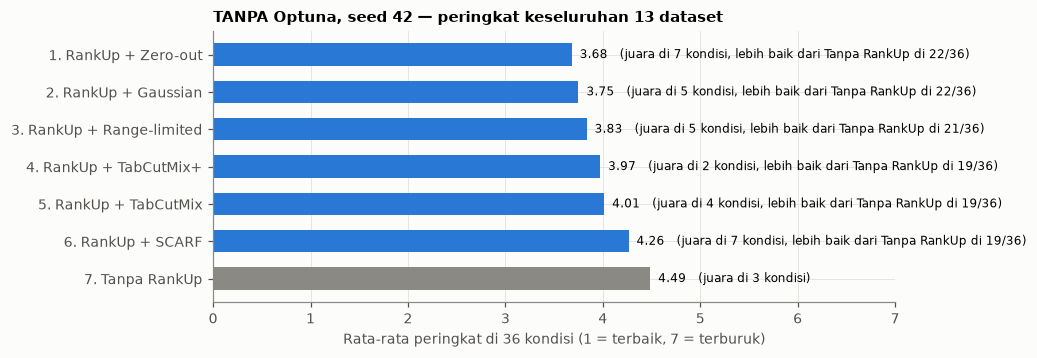

In [4]:
# Peringkat keseluruhan di semua 36 kondisi (13 dataset), dari terbaik ke terburuk.
base = data[data.metode == 'Tanpa RankUp'].set_index(['dataset', 'pct']).test
data['lebih_baik'] = (data.test - base.reindex(list(zip(data.dataset, data.pct))).values) * data.sign > 0
total = data.groupby('metode').agg(rank=('rank', 'mean'), menang=('lebih_baik', 'sum'), n=('rank', 'size'),
                                   juara=('rank', lambda r: int((r == 1).sum()))).sort_values('rank')
fig, ax = plt.subplots(figsize=(8, 3.2))
label = [f'{i}. {m}' for i, m in enumerate(total.index, start=1)]
ax.barh(label, total['rank'], color=['#8a8984' if m == 'Tanpa RankUp' else '#2a78d6' for m in total.index], height=0.6)
for i, (m, r) in enumerate(total.iterrows()):
    teks = f"  {r['rank']:.2f}   (juara di {int(r.juara)} kondisi"
    teks += ')' if m == 'Tanpa RankUp' else f", lebih baik dari Tanpa RankUp di {int(r.menang)}/{int(r.n)})"
    ax.text(r['rank'], i, teks, va='center', fontsize=8)
ax.invert_yaxis(); ax.set_xlim(0, 7)
ax.set_xlabel('Rata-rata peringkat di 36 kondisi (1 = terbaik, 7 = terburuk)')
ax.set_title('TANPA Optuna, seed 42 — peringkat keseluruhan 13 dataset')
simpan(fig, '2d_peringkat_keseluruhan')
display(total.rename(columns={'rank': 'rata-rata peringkat', 'juara': 'jumlah #1',
                              'menang': 'lebih baik dari Tanpa RankUp', 'n': 'kondisi'}).round(2))

- Urutan keseluruhan ada di grafik di atas; selisih rata-rata peringkat antar augmentasi kecil.
- Manfaat terbesar saat label 1%: NHANES, Pen Digits, Diabetes dan Melbourne 1% hampir semua RankUp lebih baik.
- Tanpa RankUp justru termasuk yang terbaik di CMC 10%, Grid Stability 10%, Student Performance 10%
  dan Bank Marketing 1%.

## 3. TANPA Optuna, 1 seed (42): RankUp vs metode lain tanpa RankUp

RankUp ditampilkan sebagai **rentang** 6 augmentasi (garis = terburuk–terbaik, titik = rata-rata), supaya tidak hanya
memilih yang terbaik di test. Untuk MSE sumbu dibalik, jadi di semua panel **kanan = lebih baik**.
SSL deep (VIME, SSLAE, GFTab, STUNT) hanya berlaku untuk ordinal/klasifikasi.

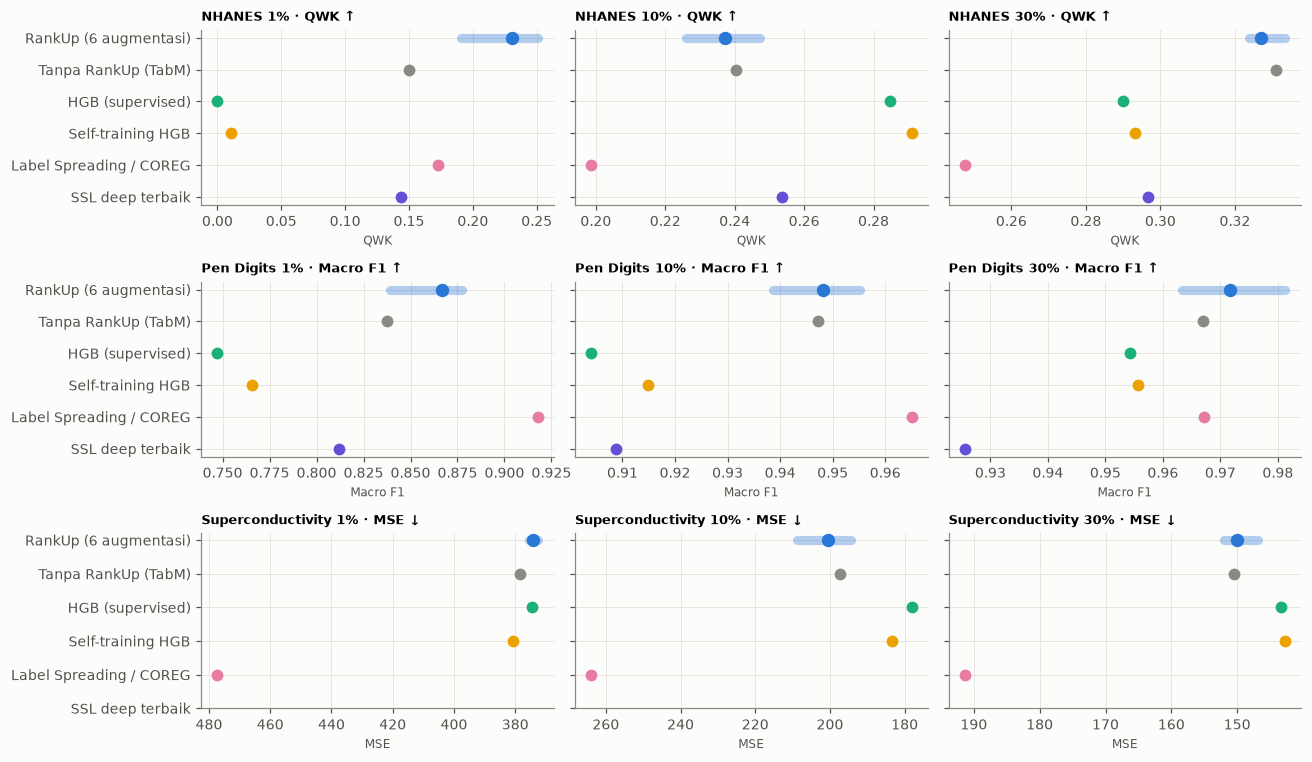

In [5]:
pb = pd.read_csv(HASIL / 'pembanding' / 'peringkat.csv')
pb['skor'] = pb.value * pb.sign
deep = pb[pb.name.isin(['VIME', 'SSLAE', 'GFTAB', 'STUNT'])]
deep_best = deep.loc[deep.groupby(['dataset', 'pct']).skor.idxmax()].assign(name='SSL deep terbaik')
lain = pd.concat([pb[pb.name.isin(['HGB (supervised)', 'Self-training HGB', 'Label Spreading', 'COREG'])], deep_best])
lain['name'] = lain.name.replace({'Label Spreading': 'Label Spreading / COREG', 'COREG': 'Label Spreading / COREG'})
PEMBANDING = {'Tanpa RankUp (TabM)': '#8a8984', 'HGB (supervised)': '#1baf7a', 'Self-training HGB': '#eda100',
              'Label Spreading / COREG': '#e87ba4', 'SSL deep terbaik': '#6250d6'}
base3 = data[data.metode == 'Tanpa RankUp'].set_index(['dataset', 'pct']).test
rankup = data[data.metode != 'Tanpa RankUp']

fig, axes = plt.subplots(3, 3, figsize=(12, 7))
for r, ds in enumerate(NAMA_DS):
    for c, pct in enumerate((1, 10, 30)):
        ax = axes[r, c]
        aug = rankup[(rankup.dataset == ds) & (rankup.pct == pct)].test
        ax.plot([aug.min(), aug.max()], [0, 0], color='#2a78d6', lw=6, solid_capstyle='round', alpha=0.35)
        ax.scatter(aug.mean(), 0, s=60, color='#2a78d6', zorder=3)
        titik = {'Tanpa RankUp (TabM)': base3.loc[(ds, pct)]}
        titik.update(lain[(lain.dataset == ds) & (lain.pct == pct)].set_index('name').value.to_dict())
        for i, (nm, warna) in enumerate(PEMBANDING.items(), start=1):
            if nm in titik:
                ax.scatter(titik[nm], i, s=45, color=warna, zorder=3)
        ax.set_yticks(range(len(PEMBANDING) + 1), ['RankUp (6 augmentasi)'] + list(PEMBANDING) if c == 0 else [])
        ax.invert_yaxis()
        if ds == 'superconductivity':
            ax.invert_xaxis()
        metrik = {'nhanes': 'QWK ↑', 'pendigits': 'Macro F1 ↑', 'superconductivity': 'MSE ↓'}[ds]
        ax.set_title(f'{NAMA_DS[ds]} {pct}% · {metrik}', fontsize=8.5)
        ax.set_xlabel(metrik.rsplit(' ', 1)[0], fontsize=8)
fig.tight_layout()
simpan(fig, '3_vs_metode_lain')

- RankUp selalu lebih baik dari **SSL deep** (VIME, SSLAE, GFTab, STUNT).
- **HGB / Self-training HGB** mengalahkan semua varian RankUp di Superconductivity 10–30% (MSE ±178–183 vs ≥194)
  dan NHANES 10% (QWK 0.285–0.291 vs ≤0.247).
- **Label Spreading** mengalahkan semua varian RankUp di Pen Digits 1% dan 10% (F1 0.918 dan 0.965).

## 4. DENGAN Optuna 40 trial, 5 seed: tiga dataset utama

Untuk tiap augmentasi × dataset × % label: Optuna 40 trial mencari kekuatan augmentasi terbaik di **validation**,
lalu model dilatih ulang dengan 5 seed (42, 123, 456, 789, 101112). Run ini **tidak punya** Tanpa RankUp;
pembanding Tanpa RankUp di §4.4 diambil dari run seed 42 di §1.

### 4.1 Rata-rata ± std 5 seed (test)

Sel: rata-rata ± std dari 5 seed, lalu peringkat di kolom itu (#1 = terbaik, cara membaca sama seperti §1).

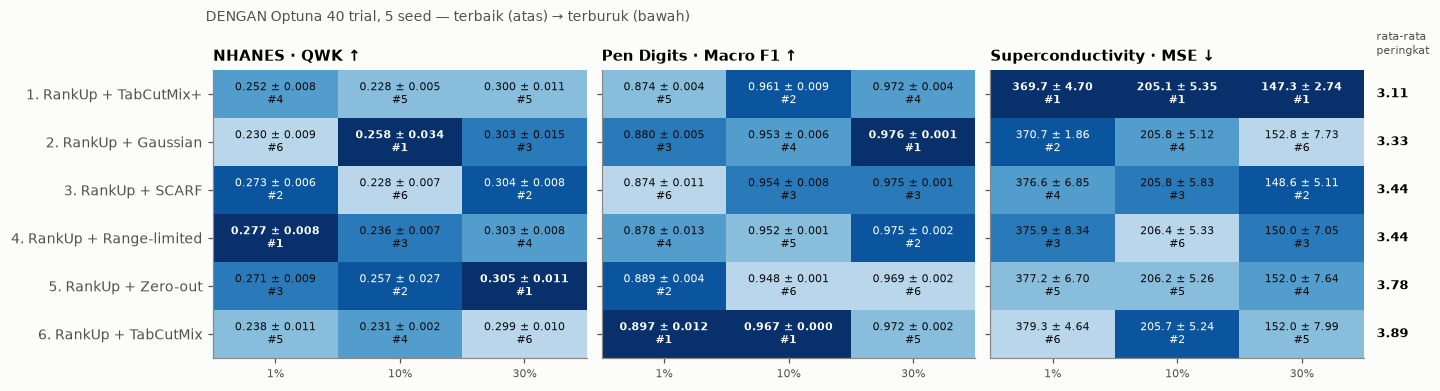

In [6]:
lama = pd.read_csv(HASIL / 'ringkasan-5seed-40trial.csv')
SEED = ['seed_42', 'seed_123', 'seed_456', 'seed_789', 'seed_101112']
MENTAH = {METODE['def_' + m]: m for m in lama.method.unique()}
LABEL_DS = {'nhanes': 'QWK ↑', 'pendigits': 'Macro F1 ↑', 'superconductivity': 'MSE ↓'}
opt = pd.DataFrame({'metode': lama.method.map(lambda m: METODE['def_' + m]), 'dataset': lama.dataset,
                    'pct': lama.label_percent, 'test': lama['mean'], 'std': lama['std'],
                    'sign': np.where(lama.dataset == 'superconductivity', -1, 1)})
opt['rank'] = (opt.test * opt.sign).groupby([opt.dataset, opt.pct]).rank(ascending=False)
urut_opt = urutan(opt)

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.4), sharey=True, gridspec_kw={'wspace': 0.04})
for ax, ds in zip(axes, NAMA_DS):
    tabel_warna(ax, opt[opt.dataset == ds], urut_opt, kanan=ds == 'superconductivity')
    ax.set_xticks(range(3), ['1%', '10%', '30%'])
    ax.set_title(f'{NAMA_DS[ds]} · {LABEL_DS[ds]}')
fig.suptitle('DENGAN Optuna 40 trial, 5 seed — terbaik (atas) → terburuk (bawah)', x=0.12, ha='left', y=1.04, fontsize=9,
             color='#52514e')
simpan(fig, '4a_optuna_5seed_tabel')

### 4.2 Peringkat keseluruhan (9 kondisi)

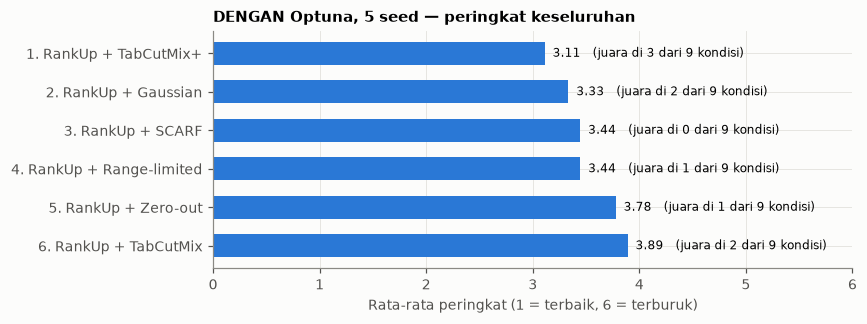

In [7]:
tot = opt.groupby('metode').agg(rank=('rank', 'mean'), juara=('rank', lambda r: int((r == 1).sum()))).sort_values('rank')
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.barh([f'{i}. {m}' for i, m in enumerate(tot.index, start=1)], tot['rank'], color='#2a78d6', height=0.6)
for i, (r, j) in enumerate(zip(tot['rank'], tot.juara)):
    ax.text(r, i, f'  {r:.2f}   (juara di {j} dari 9 kondisi)', va='center', fontsize=8)
ax.invert_yaxis(); ax.set_xlim(0, 6)
ax.set_xlabel('Rata-rata peringkat (1 = terbaik, 6 = terburuk)')
ax.set_title('DENGAN Optuna, 5 seed — peringkat keseluruhan')
simpan(fig, '4b_optuna_5seed_peringkat')

Urutan dengan Optuna (TabCutMix+ teratas) **berbeda** dengan tanpa Optuna di §1 (Range-limited teratas),
dan selisih rata-rata peringkatnya kecil (3.11–3.89).

### 4.3 Sebaran 5 seed

Titik biru muda = skor tiap seed, garis hitam = rata-rata. Jika titik antar metode saling tumpang tindih,
selisih antar augmentasi lebih kecil dari variasi seed. Untuk MSE sumbu dibalik (**kanan = lebih baik** di semua panel).

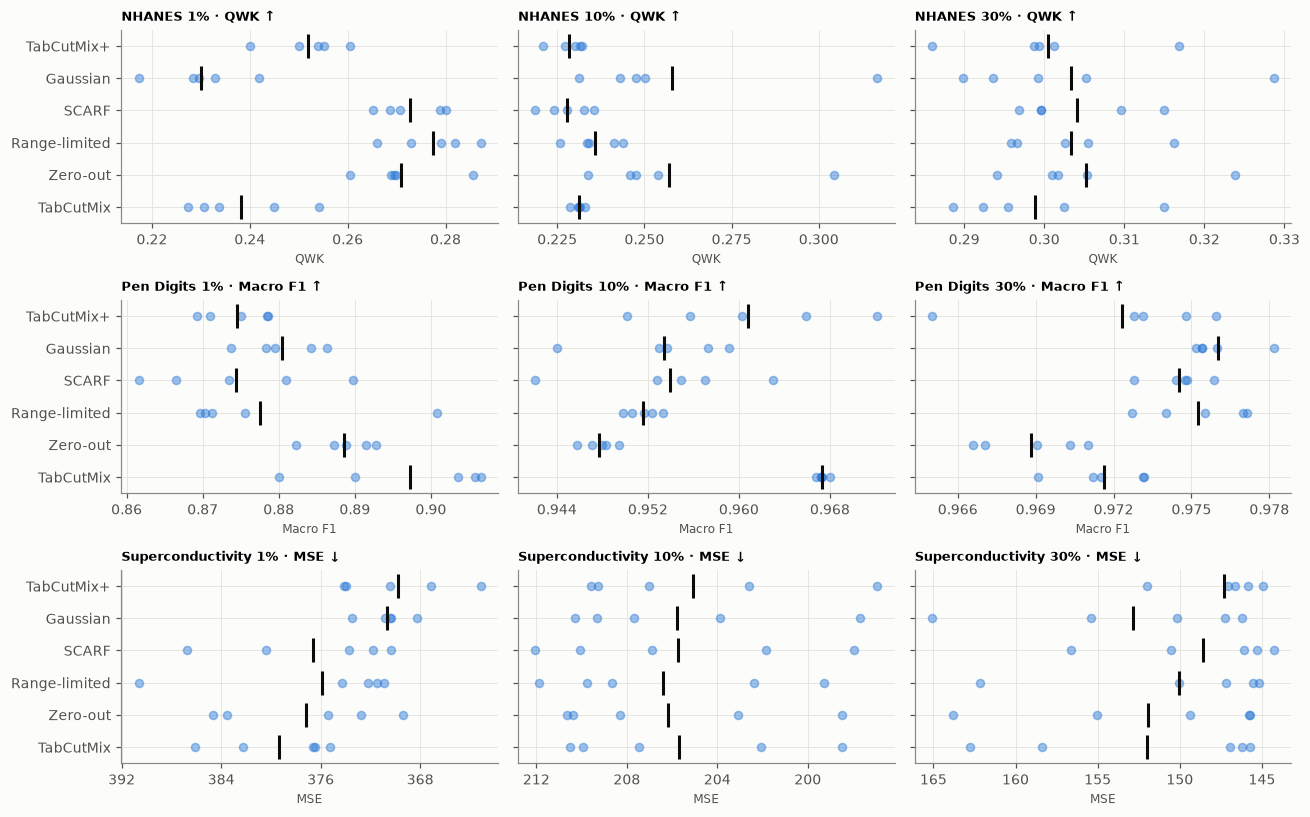

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(12, 7.5))
for r, ds in enumerate(NAMA_DS):
    for c, pct in enumerate((1, 10, 30)):
        ax = axes[r, c]
        d = lama[(lama.dataset == ds) & (lama.label_percent == pct)].set_index('method')
        for i, nm in enumerate(urut_opt.index):
            nilai_seed = d.loc[MENTAH[nm], SEED].astype(float)
            ax.scatter(nilai_seed, [i] * len(SEED), s=28, color='#2a78d6', alpha=0.45, zorder=3)
            ax.scatter(nilai_seed.mean(), i, s=260, marker='|', color='#0b0b0b', linewidths=2, zorder=4)
        ax.set_yticks(range(len(urut_opt)), urut_opt.index.str.replace('RankUp + ', '') if c == 0 else [])
        ax.set_ylim(len(urut_opt) - 0.5, -0.5)
        if ds == 'superconductivity':
            ax.invert_xaxis()
        ax.set_title(f'{NAMA_DS[ds]} {pct}% · {LABEL_DS[ds]}', fontsize=8.5)
        ax.set_xlabel(LABEL_DS[ds].rsplit(' ', 1)[0], fontsize=8)
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
fig.tight_layout()
simpan(fig, '4c_optuna_5seed_sebaran')

- Di Superconductivity dan NHANES 30% titik-titik antar augmentasi saling tumpang tindih: urutan augmentasi bisa
  berubah hanya karena ganti seed (Superconductivity 10%: semua augmentasi tersebar di MSE ±197–212).
- Di Pen Digits dan NHANES 1% titiknya lebih terpisah: di sana pilihan augmentasi memang berpengaruh.
  Contoh: **TabCutMix di Pen Digits 10%** (0.967, kelima seed hampir sama). Rinciannya di §4.6.

### 4.4 Optuna vs tanpa Optuna (sama-sama seed 42)

Titik penuh = **dengan Optuna**, titik kosong = **tanpa Optuna** (weak = 0, strong = 0.5).
Garis putus-putus abu-abu = **Tanpa RankUp**. Kanan = lebih baik di semua panel.

,Optuna lebih baik,kondisi
metode,,
RankUp + TabCutMix+,6,9
RankUp + Gaussian,6,9
RankUp + SCARF,5,9
RankUp + Range-limited,4,9
RankUp + Zero-out,6,9
RankUp + TabCutMix,6,9


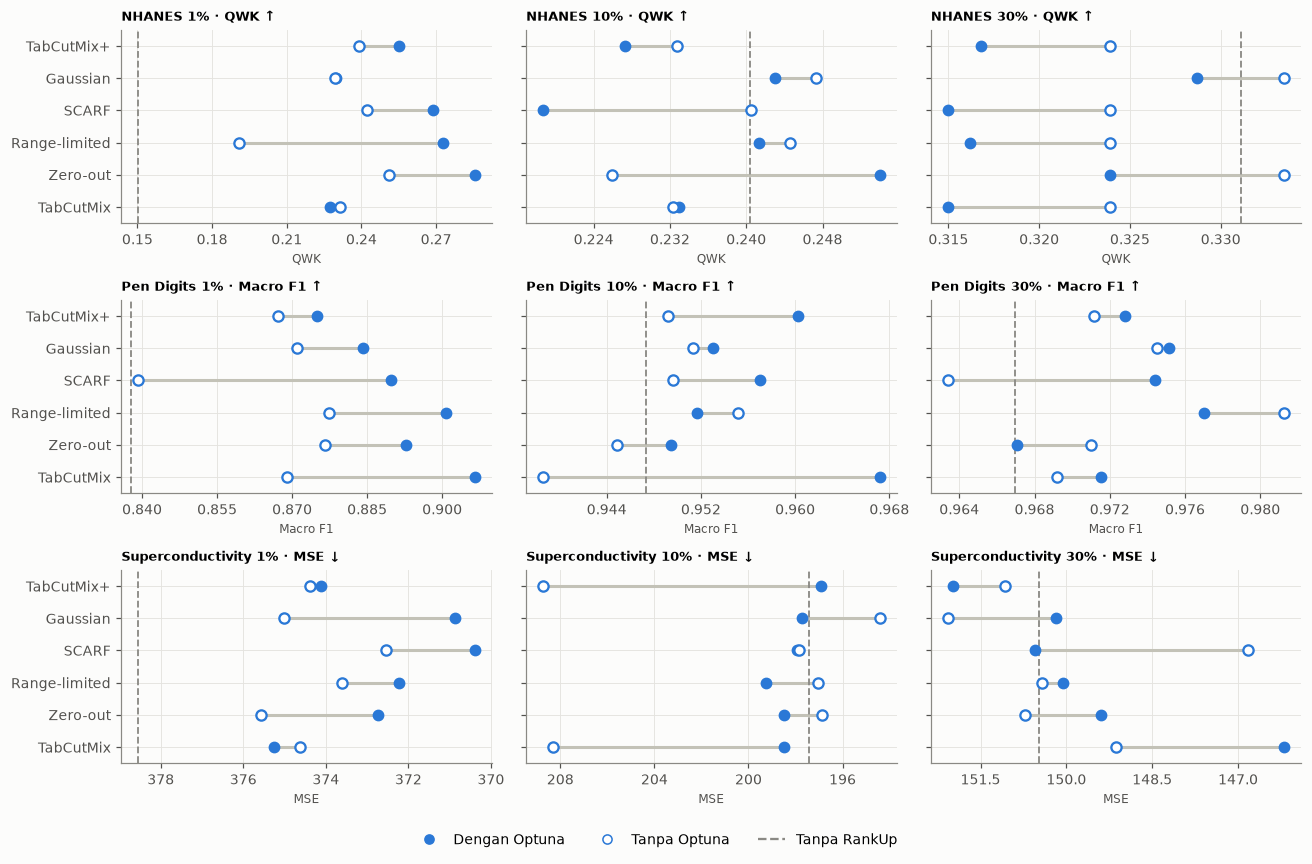

In [9]:
none42 = data[data.metode == 'Tanpa RankUp'].set_index(['dataset', 'pct']).test
tanpa = data.set_index(['metode', 'dataset', 'pct']).test
banding = []
fig, axes = plt.subplots(3, 3, figsize=(12, 7.5))
for r, ds in enumerate(NAMA_DS):
    for c, pct in enumerate((1, 10, 30)):
        ax = axes[r, c]
        d = lama[(lama.dataset == ds) & (lama.label_percent == pct)].set_index('method')
        for i, nm in enumerate(urut_opt.index):
            a, b = d.at[MENTAH[nm], 'seed_42'], tanpa.loc[(nm, ds, pct)]
            ax.plot([a, b], [i, i], color='#c3c2b7', lw=2)
            ax.scatter(a, i, s=45, color='#2a78d6', zorder=3)
            ax.scatter(b, i, s=45, facecolor='white', edgecolor='#2a78d6', lw=1.5, zorder=3)
            sign = -1 if ds == 'superconductivity' else 1
            banding.append({'metode': nm, 'Optuna lebih baik': (a - b) * sign > 0})
        ax.axvline(none42.loc[(ds, pct)], color='#8a8984', ls='--', lw=1.2)
        ax.set_yticks(range(len(urut_opt)), urut_opt.index.str.replace('RankUp + ', '') if c == 0 else [])
        ax.set_ylim(len(urut_opt) - 0.5, -0.5)
        if ds == 'superconductivity':
            ax.invert_xaxis()
        ax.set_title(f'{NAMA_DS[ds]} {pct}% · {LABEL_DS[ds]}', fontsize=8.5)
        ax.set_xlabel(LABEL_DS[ds].rsplit(' ', 1)[0], fontsize=8)
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
fig.legend(handles=[plt.Line2D([], [], marker='o', ls='', color='#2a78d6', label='Dengan Optuna'),
                    plt.Line2D([], [], marker='o', ls='', mfc='white', mec='#2a78d6', label='Tanpa Optuna'),
                    plt.Line2D([], [], ls='--', color='#8a8984', label='Tanpa RankUp')],
           loc='upper center', ncol=3, bbox_to_anchor=(0.5, 0))
fig.tight_layout()
simpan(fig, '4d_optuna_vs_tanpa_optuna')
hasil = pd.DataFrame(banding).groupby('metode')['Optuna lebih baik'].agg(['sum', 'size'])
display(hasil.loc[urut_opt.index].rename(columns={'sum': 'Optuna lebih baik', 'size': 'kondisi'}))

- Optuna lebih baik di **33 dari 54** pasangan (6 augmentasi × 9 kondisi), jadi membantu tetapi tidak selalu.
- **Pen Digits 1%**: Optuna lebih baik untuk keenam augmentasi.
- **NHANES 30%**: Optuna justru lebih buruk untuk keenam augmentasi, dan semuanya di bawah Tanpa RankUp (QWK 0.331).
- Range-limited paling jarang terbantu Optuna (4 dari 9).

### 4.5 Parameter terbaik hasil Optuna

In [10]:
rows = []
for f in sorted(HASIL.glob('ta-5seed-40trial-20261105/label_*/tuning/*/*_best_params.json')):
    j = json.loads(f.read_text())
    rows.append({'dataset': NAMA_DS[j['dataset']], '% label': round(j['labeled_fraction'] * 100),
                 'metode': METODE['def_' + f.name.replace('_best_params.json', '').replace('rankup_cls_', '')
                                  .replace('rankup_', '')],
                 'parameter terbaik': ', '.join(f'{k} = {v:.3g}' if isinstance(v, float) else f'{k} = {v}'
                                                for k, v in j['parameters'].items()),
                 'trial selesai / dipangkas': f"{j['trial_counts']['complete']} / {j['trial_counts']['pruned']}"})
pd.set_option('display.max_rows', 100, 'display.max_colwidth', 120)
display(pd.DataFrame(rows).sort_values(['dataset', '% label', 'metode']).set_index(['dataset', '% label', 'metode']))

parameter terbaik  \
dataset           % label metode                                                                  
NHANES            1       RankUp + Gaussian            weak_sigma = 0.652, relative_gap = 0.619   
                          RankUp + Range-limited   weak_strength = 0.163, relative_gap = 0.0243   
                          RankUp + SCARF                       weak_q = 6, relative_gap = 0.184   
                          RankUp + TabCutMix       weak_strength = 0.169, relative_gap = 0.0397   
                          RankUp + TabCutMix+     weak_strength = 0.0413, relative_gap = 0.0592   
                          RankUp + Zero-out         weak_strength = 0.271, relative_gap = 0.278   
                  10      RankUp + Gaussian          weak_sigma = 0.00781, relative_gap = 0.915   
                          RankUp + Range-limited    weak_strength = 0.644, relative_gap = 0.302   
                          RankUp + SCARF                       weak_q = 1, relative_gap = 0.817   
                          RankUp + TabCutMix        weak_strength = 0.605, relative_gap = 0.717   
                          RankUp + TabCutMix+       weak_strength = 0.762, relative_gap = 0.522   
                          RankUp + Zero-out        weak_strength = 0.0911, relative_gap = 0.473   
                  30      RankUp + Gaussian              weak_sigma = 1.07, relative_gap = 0.12   
                          RankUp + Range-limited    weak_strength = 0.175, relative_gap = 0.126   
                          RankUp + SCARF                      weak_q = 11, relative_gap = 0.951   
                          RankUp + TabCutMix        weak_strength = 0.362, relative_gap = 0.951   
                          RankUp + TabCutMix+       weak_strength = 0.538, relative_gap = 0.753   
                          RankUp + Zero-out         weak_strength = 0.362, relative_gap = 0.951   
Pen Digits        1       RankUp + Gaussian         weak_sigma = 0.0191, relative_gap = 0.00553   
                          RankUp + Range-limited    weak_strength = 0.792, relative_gap = 0.213   
                          RankUp + SCARF                      weak_q = 1, relative_gap = 0.0643   
                          RankUp + TabCutMix        weak_strength = 0.922, relative_gap = 0.474   
                          RankUp + TabCutMix+       weak_strength = 0.356, relative_gap = 0.825   
                          RankUp + Zero-out        weak_strength = 0.0863, relative_gap = 0.225   
                  10      RankUp + Gaussian            weak_sigma = 0.0237, relative_gap = 0.11   
                          RankUp + Range-limited    weak_strength = 0.474, relative_gap = 0.131   
                          RankUp + SCARF                       weak_q = 6, relative_gap = 0.652   
                          RankUp + TabCutMix        weak_strength = 0.575, relative_gap = 0.708   
                          RankUp + TabCutMix+       weak_strength = 0.484, relative_gap = 0.815   
                          RankUp + Zero-out         weak_strength = 0.619, relative_gap = 0.552   
                  30      RankUp + Gaussian          weak_sigma = 0.125, relative_gap = 0.00469   
                          RankUp + Range-limited  weak_strength = 0.0165, relative_gap = 0.0758   
                          RankUp + SCARF                       weak_q = 9, relative_gap = 0.902   
                          RankUp + TabCutMix        weak_strength = 0.792, relative_gap = 0.213   
                          RankUp + TabCutMix+       weak_strength = 0.195, relative_gap = 0.793   
                          RankUp + Zero-out         weak_strength = 0.575, relative_gap = 0.708   
Superconductivity 1       RankUp + Gaussian             weak_sigma = 1.34, relative_gap = 0.748   
                          RankUp + Range-limited     weak_strength = 0.47, relative_gap = 0.473   
                          RankUp + SCARF                      weak_q = 17, relative_gap = 0.468   
                   

### 4.6 Temuan: mana yang lebih besar, pengaruh augmentasi atau pengaruh seed?

Dua angka dibandingkan di setiap kondisi, **dalam satuan metrik asli** (QWK, Macro F1, MSE):

- **Selisih augmentasi** = rata-rata 5 seed augmentasi *terbaik* dikurangi augmentasi *terburuk*.
  → seberapa besar hasil berubah kalau kita **ganti augmentasi**.
- **Rentang seed** = skor seed terbaik dikurangi seed terburuk dalam **satu** augmentasi, dirata-rata untuk 6 augmentasi.
  → seberapa besar hasil berubah kalau kita **hanya ganti seed** (augmentasi sama, data sama).

Jika rentang seed lebih besar dari selisih augmentasi, maka "augmentasi A lebih baik dari B" bisa saja hanya
kebetulan seed. Untuk memastikannya dipakai **uji ANOVA satu arah** (6 augmentasi × 5 seed):
p < 0.05 berarti rata-rata augmentasi **benar-benar berbeda**; p ≥ 0.05 berarti perbedaannya **masih bisa dijelaskan
oleh variasi seed**.

Metrik     Augmentasi terbaik  \
Dataset           % label                                    
NHANES            1             QWK  Range-limited (0.277)   
                  10            QWK       Gaussian (0.258)   
                  30            QWK       Zero-out (0.305)   
Pen Digits        1        Macro F1      TabCutMix (0.897)   
                  10       Macro F1      TabCutMix (0.967)   
                  30       Macro F1       Gaussian (0.976)   
Superconductivity 1             MSE     TabCutMix+ (369.7)   
                  10            MSE     TabCutMix+ (205.1)   
                  30            MSE     TabCutMix+ (147.3)   

                             Augmentasi terburuk Selisih augmentasi  \
Dataset           % label                                             
NHANES            1             Gaussian (0.230)              0.047   
                  10               SCARF (0.228)              0.030   
                  30           TabCutMix (0.299)              0.006   
Pen Digits        1                SCARF (0.874)              0.023   
                  10            Zero-out (0.948)              0.020   
                  30            Zero-out (0.969)              0.007   
Superconductivity 1            TabCutMix (379.3)               9.58   
                  10       Range-limited (206.4)               1.31   
                  30            Gaussian (152.8)               5.53   

                          Rentang seed Lebih besar p (ANOVA)  \
Dataset           % label                                      
NHANES            1              0.022  augmentasi   < 0.001   
                  10             0.034        seed     0.033   
                  30             0.027        seed     0.938   
Pen Digits        1              0.020  augmentasi     0.003   
                  10             0.011  augmentasi   < 0.001   
                  30             0.005  augmentasi   < 0.001   
Superconductivity 1               13.1        seed     0.099   
                  10              12.7        seed     0.999   
                  30              15.1        seed     0.741   

                                         Kesimpulan  
Dataset           % label                            
NHANES            1        augmentasi berbeda nyata  
                  10       augmentasi berbeda nyata  
                  30          bisa karena seed saja  
Pen Digits        1        augmentasi berbeda nyata  
                  10       augmentasi berbeda nyata  
                  30       augmentasi berbeda nyata  
Superconductivity 1           bisa karena seed saja  
                  10          bisa karena seed saja  
                  30          bisa karena seed saja

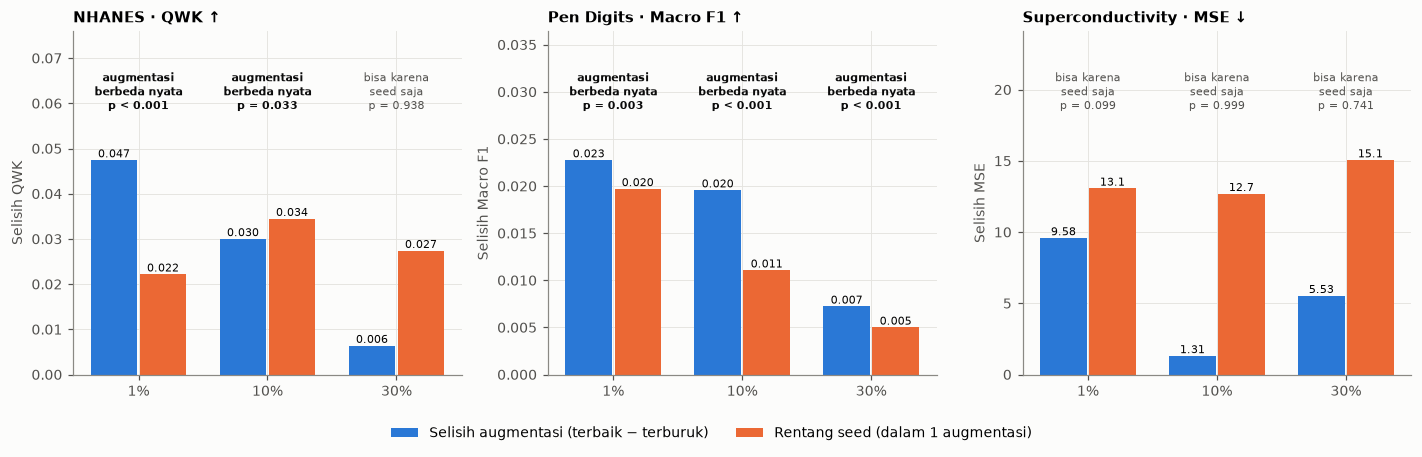

In [11]:
from scipy.stats import f_oneway

PENDEK = {m: METODE['def_' + m].replace('RankUp + ', '') for m in lama.method.unique()}
baris = []
for (ds, pct), g in lama.groupby(['dataset', 'label_percent']):
    v = g.set_index('method')[SEED].astype(float)
    rata = v.mean(axis=1)
    arah = -1 if ds == 'superconductivity' else 1
    terbaik, terburuk = (rata * arah).idxmax(), (rata * arah).idxmin()
    baris.append({'dataset': ds, 'pct': pct, 'metrik': LABEL_DS[ds].split(' ')[0] if ds != 'pendigits' else 'Macro F1',
                  'terbaik': terbaik, 'nilai_terbaik': rata[terbaik], 'terburuk': terburuk,
                  'nilai_terburuk': rata[terburuk], 'selisih_aug': rata.max() - rata.min(),
                  'rentang_seed': (v.max(axis=1) - v.min(axis=1)).mean(), 'p': f_oneway(*v.values).pvalue})
var = pd.DataFrame(baris)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, ds in zip(axes, NAMA_DS):
    d = var[var.dataset == ds].reset_index(drop=True)
    x = np.arange(len(d))
    ax.bar(x - 0.19, d.selisih_aug, width=0.36, color='#2a78d6', label='Selisih augmentasi (terbaik − terburuk)')
    ax.bar(x + 0.19, d.rentang_seed, width=0.36, color='#eb6834', label='Rentang seed (dalam 1 augmentasi)')
    tinggi = max(d.selisih_aug.max(), d.rentang_seed.max())
    for i, r in d.iterrows():
        ax.text(i - 0.19, r.selisih_aug, angka(r.selisih_aug), ha='center', va='bottom', fontsize=7.5)
        ax.text(i + 0.19, r.rentang_seed, angka(r.rentang_seed), ha='center', va='bottom', fontsize=7.5)
        nyata = r.p < 0.05
        ax.text(i, tinggi * 1.22, ('augmentasi\nberbeda nyata' if nyata else 'bisa karena\nseed saja') + ('\np < 0.001' if r.p < 0.001 else f'\np = {r.p:.3f}'),
                ha='center', va='bottom', fontsize=7.5, color='#0b0b0b' if nyata else '#52514e',
                fontweight='bold' if nyata else 'normal')
    ax.set_ylim(0, tinggi * 1.6)
    ax.set_xticks(x, [f'{p}%' for p in d.pct])
    ax.set_ylabel(f'Selisih {d.metrik.iat[0]}')
    ax.set_title(f'{NAMA_DS[ds]} · {LABEL_DS[ds]}')
fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=2, bbox_to_anchor=(0.5, 0))
fig.tight_layout()
simpan(fig, '4e_variasi_seed_vs_augmentasi')

tabel = pd.DataFrame({
    'Dataset': var.dataset.map(NAMA_DS), '% label': var.pct, 'Metrik': var.metrik,
    'Augmentasi terbaik': [f'{PENDEK[m]} ({angka(v)})' for m, v in zip(var.terbaik, var.nilai_terbaik)],
    'Augmentasi terburuk': [f'{PENDEK[m]} ({angka(v)})' for m, v in zip(var.terburuk, var.nilai_terburuk)],
    'Selisih augmentasi': var.selisih_aug.map(angka), 'Rentang seed': var.rentang_seed.map(angka),
    'Lebih besar': np.where(var.rentang_seed > var.selisih_aug, 'seed', 'augmentasi'),
    'p (ANOVA)': var.p.map(lambda p: '< 0.001' if p < 0.001 else f'{p:.3f}'),
    'Kesimpulan': np.where(var.p < 0.05, 'augmentasi berbeda nyata', 'bisa karena seed saja')})
display(tabel.set_index(['Dataset', '% label']))

**Temuan:**

1. **Superconductivity (semua % label): pilihan augmentasi tidak berpengaruh nyata** (p = 0.10, 0.999, 0.74).
   - 10%: augmentasi terbaik (TabCutMix+, MSE 205.1) dan terburuk (Range-limited, 206.4) hanya beda **1.3 MSE**,
     padahal ganti seed saja bisa mengubah MSE sekitar **12.7**.
   - 30%: beda augmentasi 5.5 MSE, beda seed 15.1 MSE.
2. **NHANES 30%: juga tidak berpengaruh nyata** (p = 0.94). Beda augmentasi hanya **0.006 QWK**
   (Zero-out 0.305 vs TabCutMix 0.299), sedangkan beda seed **0.027 QWK**.
3. **NHANES 10%: tipis** (p = 0.03). Beda augmentasi 0.030 QWK, tetapi beda seed lebih besar (0.034 QWK).
4. **Pen Digits (semua %) dan NHANES 1%: augmentasi berbeda nyata** (p ≤ 0.003).
   - NHANES 1%: Range-limited 0.277 vs Gaussian 0.230 (beda **0.047 QWK**; seed hanya 0.022).
   - Pen Digits 10%: TabCutMix 0.967 vs Zero-out 0.948 (beda **0.020 F1**; seed hanya 0.011).

**Artinya:** di 5 dari 9 kondisi, variasi karena seed lebih besar daripada perbedaan antar augmentasi, dan di
4 kondisi (semua Superconductivity + NHANES 30%) perbedaan augmentasi tidak signifikan sama sekali.
Augmentasi baru benar-benar berpengaruh saat label sedikit dan pada data klasifikasi (Pen Digits).
Karena itu, klaim "augmentasi X terbaik" harus didukung **beberapa seed + uji statistik**, bukan satu run.

### 4.7 Ringkasan untuk slide: dua contoh

Setiap baris = satu augmentasi; **titik berwarna = skor tiap seed** (warna sama = seed sama), **garis hitam = rata-rata**.
**Pita biru muda** = rentang tempat semua rata-rata augmentasi berada (selisih augmentasi terbaik–terburuk).

- **Kiri (Superconductivity 10%)**: titik dengan warna yang sama berbaris lurus ke bawah. Seed 42 selalu terbaik (≈197–199)
  dan seed 123/101112 selalu terburuk (≈209–212) **untuk keenam augmentasi**. Hasil ditentukan seed, bukan augmentasi.
- **Kanan (Pen Digits 10%)**: titik-titik tiap baris mengumpul dan TabCutMix terpisah jelas dari yang lain. Di sini augmentasi berpengaruh.


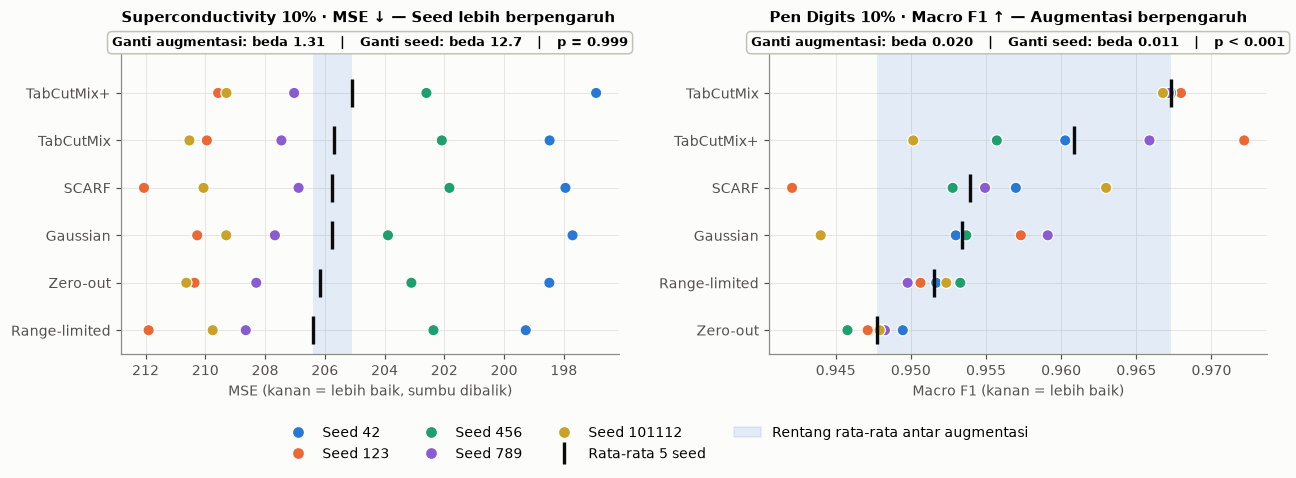

In [12]:
WARNA_SEED = ['#2a78d6', '#eb6834', '#1f9e6e', '#8a5cd1', '#c9a227']
CONTOH = [('superconductivity', 10, 'Seed lebih berpengaruh'), ('pendigits', 10, 'Augmentasi berpengaruh')]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (ds, pct, judul) in zip(axes, CONTOH):
    g = lama[(lama.dataset == ds) & (lama.label_percent == pct)].set_index('method')
    v = g[SEED].astype(float)
    rata = v.mean(axis=1)
    arah = -1 if ds == 'superconductivity' else 1
    urut = (rata * arah).sort_values(ascending=False).index  # terbaik di atas
    ax.axvspan(rata.min(), rata.max(), color='#2a78d6', alpha=0.12, lw=0)
    for i, m in enumerate(urut):
        ax.scatter(v.loc[m], [i] * len(SEED), s=55, c=WARNA_SEED, edgecolors='white', linewidths=0.8, zorder=3)
        ax.scatter(rata[m], i, s=320, marker='|', color='#0b0b0b', linewidths=2.2, zorder=4)
    ax.set_yticks(range(len(urut)), [PENDEK[m] for m in urut])
    ax.set_ylim(len(urut) - 0.5, -1.3)
    if arah == -1:
        ax.invert_xaxis()
    metrik = LABEL_DS[ds].rsplit(' ', 1)[0]
    ax.set_xlabel(f'{metrik} ({"kanan = lebih baik, sumbu dibalik" if arah == -1 else "kanan = lebih baik"})')
    sel, rent = rata.max() - rata.min(), (v.max(axis=1) - v.min(axis=1)).mean()
    p = f_oneway(*v.values).pvalue
    ax.set_title(f'{NAMA_DS[ds]} {pct}% · {LABEL_DS[ds]} — {judul}')
    ax.text(0.5, 0.985, f'Ganti augmentasi: beda {angka(sel)}   |   Ganti seed: beda {angka(rent)}   |   '
            + ('p < 0.001' if p < 0.001 else f'p = {p:.3f}'),
            transform=ax.transAxes, ha='center', va='top', fontsize=8.5, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.35', fc='#fcfcfb', ec='#c3c2b7'))
fig.legend(handles=[plt.Line2D([], [], marker='o', ls='', color=w, label=f'Seed {k[5:]}') for w, k in zip(WARNA_SEED, SEED)] + [
                    plt.Line2D([], [], marker='|', ls='', color='#0b0b0b', markersize=14, mew=2.2, label='Rata-rata 5 seed'),
                    plt.Rectangle((0, 0), 1, 1, color='#2a78d6', alpha=0.12, label='Rentang rata-rata antar augmentasi')],
           loc='upper center', ncol=4, bbox_to_anchor=(0.5, 0))
fig.tight_layout()
simpan(fig, '4f_slide_seed_vs_augmentasi')

- **Kiri (Superconductivity 10%)**: semua rata-rata augmentasi berkumpul di pita sempit (beda 1.3 MSE), sedangkan
  skor seed tersebar ±12.7 MSE. Mengganti seed jauh lebih berpengaruh daripada mengganti augmentasi (p = 0.999).
- **Kanan (Pen Digits 10%)**: titik-titik TabCutMix terpisah jelas dari augmentasi lain. Di sini pilihan augmentasi
  benar-benar berpengaruh (p < 0.001).

## Kesimpulan


1. RankUp lebih baik dari Tanpa RankUp terutama saat **label sangat sedikit (1%)**; pada 30% selisihnya kecil.
2. Augmentasi terbaik **berganti-ganti** antar dataset dan % label. Gaussian dan Zero-out paling sering membantu.
3. Gradient boosting dan Label Spreading tetap pembanding kuat yang wajib dilaporkan.
4. Dengan Optuna + 5 seed (§4) urutannya TabCutMix+ > Gaussian > SCARF ≈ Range-limited > Zero-out > TabCutMix.
   Di 5 dari 9 kondisi variasi seed lebih besar dari selisih augmentasi; di Superconductivity dan NHANES 30%
   perbedaan augmentasi tidak signifikan (§4.6). Optuna membantu di 33 dari 54 pasangan.

*§1–3 hanya satu seed; semua eksperimen memakai satu split data yang sama, jadi selisih kecil bisa karena noise.*